# Quantiva — seven-calendar-day forecasting

**Phase 3 only.** Target: daily gross eligible completed-sales revenue in GBP,
including eligible charges. Cancellations are separate movements. Zero-record dates
mean zero observed activity, not proven zero demand. Both observation boundaries
are excluded. This is a retrospective December 2011 demonstration, not live 2026 sales.

Run `quantiva forecast-train` first. This notebook demonstrates training/inference,
recomputes validation, and audits persisted held-out predictions without changing
features, model choices, calendar policy, or hyperparameters after seeing test results.


In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from quantiva.config import Settings
from quantiva.features import feature_frame
from quantiva.forecast_evaluation import SplitPlan, rolling_validation, summarize_predictions
from quantiva.forecast_series import modeled_history
from quantiva.forecasting import fit_forecaster, forecast
from quantiva.model_artifacts import forecast_saved

if os.environ.get("QUANTIVA_KERNEL_EXECUTABLE"):
    expected = Path(os.environ["QUANTIVA_KERNEL_EXECUTABLE"]).resolve()
    assert Path(sys.executable).resolve() == expected
root = Path.cwd()
while not ((root / "pyproject.toml").is_file() and (root / "src/quantiva").is_dir()):
    if root == root.parent:
        raise RuntimeError("Execute within the Quantiva checkout")
    root = root.parent
settings = Settings.from_environment()
report_dir = root / "reports"
results = json.loads((report_dir / "forecast_results.json").read_text())
table = pd.read_parquet(settings.forecast_dir / "daily_series.parquet")
history = modeled_history(table)
plan = SplitPlan()
split = plan.boundaries(history)
development = history.iloc[: split["test_start"]]
print("Python", sys.version.split()[0], "— frozen chronological experiment")

Python 3.11.9 — frozen chronological experiment


## Target construction and calendar investigation

The series aggregates validated Phase 1 eligible lines in integer GBP/10000 units.
The full-series daily totals reconcile with Phase 2 SQL. First timestamp 08:26 does
not establish complete first-day capture; it is conservatively excluded. The final
midday date is excluded as incomplete. Source-row provenance remains in the ledger.


In [2]:
display(
    pd.DataFrame([results["series"]])[
        [
            "modeling_start",
            "modeling_end",
            "full_revenue_gbp",
            "modeled_revenue_gbp",
            "excluded_boundary_revenue_gbp",
        ]
    ]
)
display(table.groupby("record_status").size().rename("calendar_dates"))
display(
    table.loc[table["record_status"].eq("no_records")]
    .groupby(table.loc[table["record_status"].eq("no_records"), "date"].dt.day_name())
    .size()
    .rename("missing_dates")
)
display(table.loc[table["boundary_excluded"]])

,modeling_start,modeling_end,full_revenue_gbp,modeled_revenue_gbp,excluded_boundary_revenue_gbp
0,2010-12-02,2011-12-08,1.064211e+07,1.038243e+07,259677.77


record_status
eligible_sales    305
no_records         69
Name: calendar_dates, dtype: int64

date
Friday        4
Monday        6
Saturday     53
Sunday        3
Thursday      1
Tuesday       1
Wednesday     1
Name: missing_dates, dtype: int64

,date,revenue_units,sale_lines,ledger_lines,record_status,boundary_excluded,revenue_gbp
0,2010-12-01,587767900,3028,3064,eligible_sales,True,58776.79
373,2011-12-09,2009009800,1618,1625,eligible_sales,True,200900.98


## Historical distribution, volatility, and trend

Development diagnostics use pretest dates only. Weekday averages and autocorrelation
are descriptive: trend, missing Saturdays, and wholesale spikes can confound them.
Month sin/cos is a known calendar feature, not proof of robust annual seasonality.


,start,end,mean_gbp,median_gbp,std_gbp,max_gbp,autocorrelation,weekday_mean_gbp,monthly_observed_revenue_gbp
0,2010-12-02,2011-10-13,24655.07612,24708.725,18988.989031,109553.9,"{'1': 0.3498477651131965, '7': 0.5984643027600...","{'0': 27177.547133333333, '1': 38870.226244444...","{'2010-12': 762675.9400000001, '2011-01': 6898..."


count       316.000000
mean      24655.076120
std       18988.989031
min           0.000000
25%        9769.262500
50%       24708.725000
75%       33802.987500
max      109553.900000
Name: revenue_gbp, dtype: float64

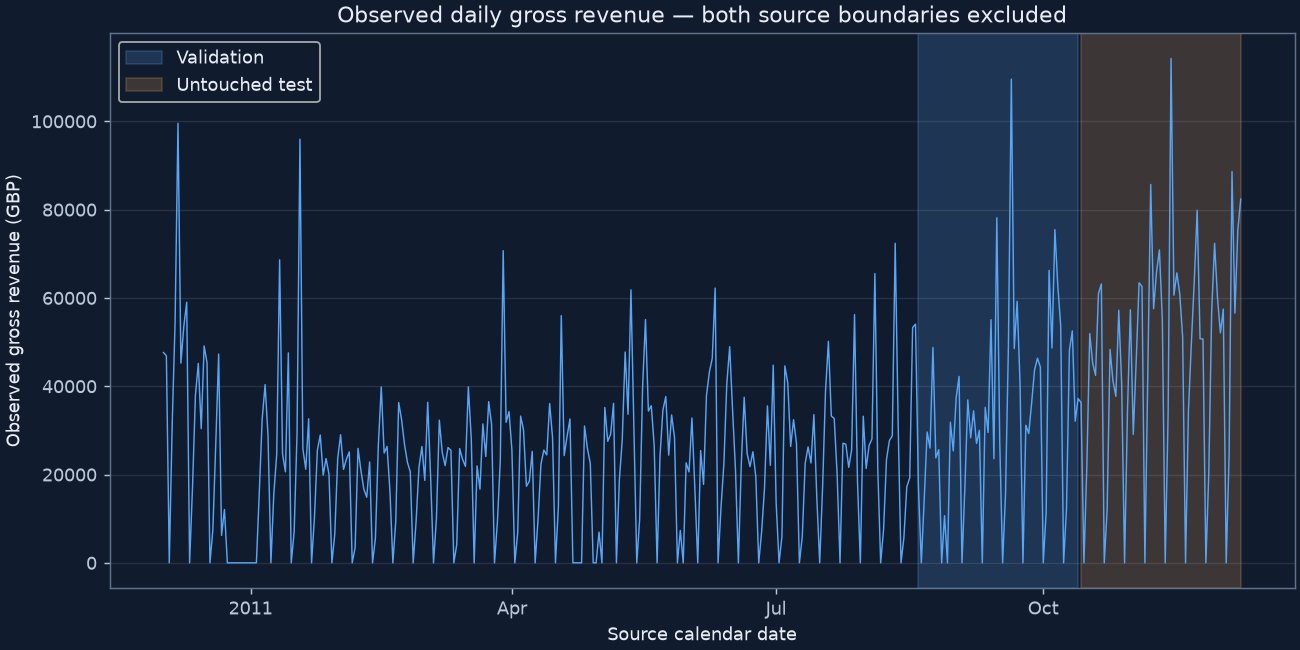

In [3]:
display(pd.DataFrame([results["development_diagnostics"]]))
display(history.loc[history.index <= development.index[-1]].describe())
display(Image(filename=str(report_dir / "figures" / "forecast_history.png")))

**Interpretation:** both source boundaries are excluded; gaps remain zero recorded
amounts. Blue validation and orange test spans are chronological. The short history
cannot establish stable annual seasonality; no inference about closure is proven.

## Features and temporal leakage

Calendar t is known ahead of time. Lag k reads t-k. Rolling means/std shift first,
using t-1 and earlier. Recursive inference replaces unavailable future lag inputs
with prior predictions. There are no future transaction, customer, or activity flags.


In [4]:
features = feature_frame(development)
display(features.dropna().head())
# Changing a target and every later value cannot change features at that target.
check = development.copy()
position = 60
before = feature_frame(check).iloc[position].copy()
check.iloc[position:] = 1e9
pd.testing.assert_series_equal(before, feature_frame(check).iloc[position])
print("Adversarial feature leakage check passed")

,weekday,month_sin,month_cos,day_of_month,lag_1,lag_7,lag_14,lag_28,mean_7,mean_14,mean_28,std_7,trend_7_28
date,,,,,,,,,,,,,
2010-12-30,3,-2.449294e-16,1.000000,30,0.0,12071.91,49114.14,47629.42,1724.558571,13870.052857,27238.426429,4562.753101,-25513.867857
2010-12-31,4,-2.449294e-16,1.000000,31,0.0,0.00,45338.13,46898.63,0.000000,10361.900000,25537.375714,0.000000,-25537.375714
2011-01-01,5,5.000000e-01,0.866025,1,0.0,0.00,0.00,0.00,0.000000,7123.462143,23862.424643,0.000000,-23862.424643
2011-01-02,6,5.000000e-01,0.866025,2,0.0,0.00,7410.47,31364.63,0.000000,7123.462143,23862.424643,0.000000,-23862.424643
2011-01-03,0,5.000000e-01,0.866025,3,0.0,0.00,26766.23,54624.15,0.000000,6594.142857,22742.259286,0.000000,-22742.259286


Adversarial feature leakage check passed


## Baselines and expanding-window validation

Naive repeats the last calendar observation, which can be zero. Weekly seasonal
naive copies matching dates from the previous week. Both predict the whole week
without any actual from their prediction window. Validation uses eight disjoint
weekly windows, refitting on expanding past history. Earlier validation observations
can enter later fold histories only after their dates have passed.


,date,horizon,prediction_gbp,model
0,2011-08-19,1,54059.1,naive
1,2011-08-20,2,54059.1,naive
2,2011-08-21,3,54059.1,naive
3,2011-08-22,4,54059.1,naive
4,2011-08-23,5,54059.1,naive
5,2011-08-24,6,54059.1,naive
6,2011-08-25,7,54059.1,naive


,date,horizon,prediction_gbp,model
0,2011-08-19,1,32231.35,seasonal_naive
1,2011-08-20,2,0.00,seasonal_naive
2,2011-08-21,3,5701.87,seasonal_naive
3,2011-08-22,4,17235.95,seasonal_naive
4,2011-08-23,5,19234.53,seasonal_naive
5,2011-08-24,6,53284.76,seasonal_naive
6,2011-08-25,7,54059.10,seasonal_naive


,validation_start,test_start,training_start_date,initial_training_end_date,validation_start_date,validation_end_date,test_start_date,test_end_date
0,260,316,2010-12-02,2011-08-18,2011-08-19,2011-10-13,2011-10-14,2011-12-08


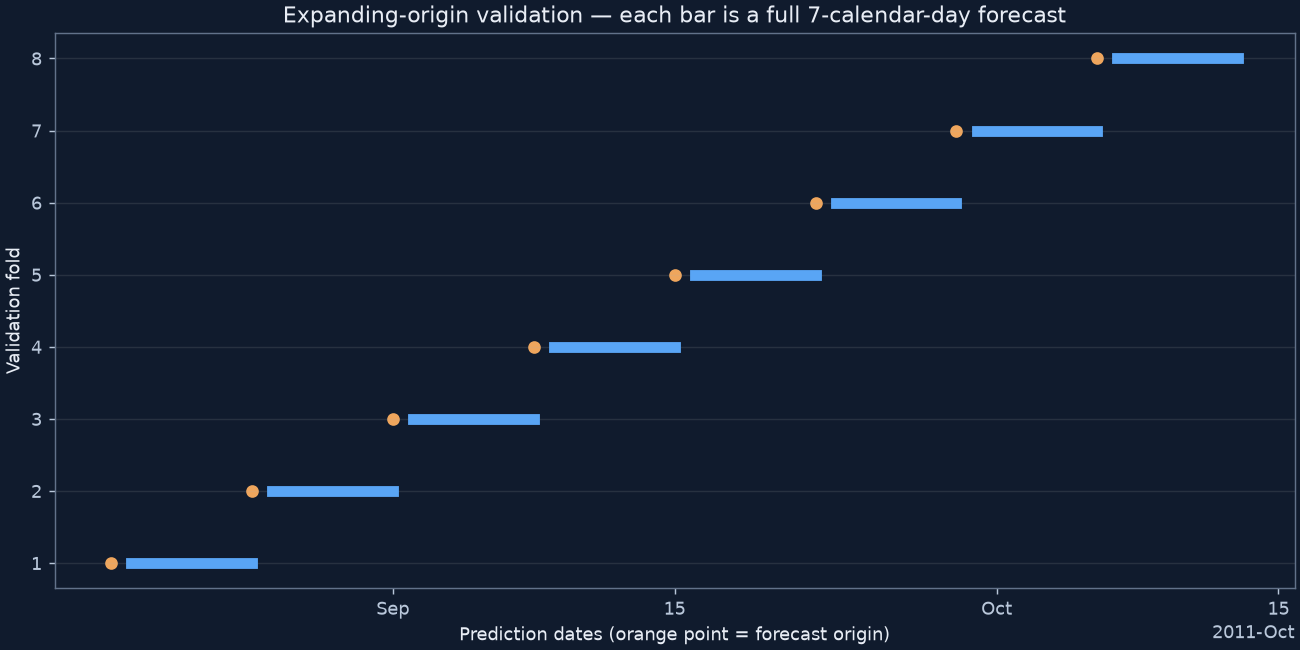

In [5]:
initial = development.iloc[: split["validation_start"]]
for model_name in ["naive", "seasonal_naive"]:
    model = fit_forecaster(initial, model_name)
    display(forecast(model, initial)[["date", "horizon", "prediction_gbp", "model"]])
display(pd.DataFrame([split]))
display(Image(filename=str(report_dir / "figures" / "forecast_windows.png")))

**Interpretation:** each bar is seven prediction dates and the orange point is its
origin. Entire forecast windows remain unavailable during inference. No random split
is used, and final test dates never enter validation.

## Regression training and primary validation comparison

OLS estimates a linear conditional relationship after weekday encoding/numeric scaling.
Correlated lags make coefficients unstable and noncausal. Random forests average trees
with nonlinear interactions; small data and spikes can still overfit. Fixed settings:
120 trees, depth 6, leaf minimum 5, random seed 42. No test-driven hyperparameter search.


,experiment,model,mae_gbp,rmse_gbp,wape_pct,bias_gbp,observations
0,primary,linear_regression,12792.966806,18258.305860,39.570141,-5324.387935,56
1,primary,naive,24181.770143,30305.705676,74.797041,16260.736214,56
2,primary,random_forest,11431.529500,17764.131098,35.359057,-4906.076009,56
3,primary,seasonal_naive,15580.520179,21661.318859,48.192369,-967.724821,56


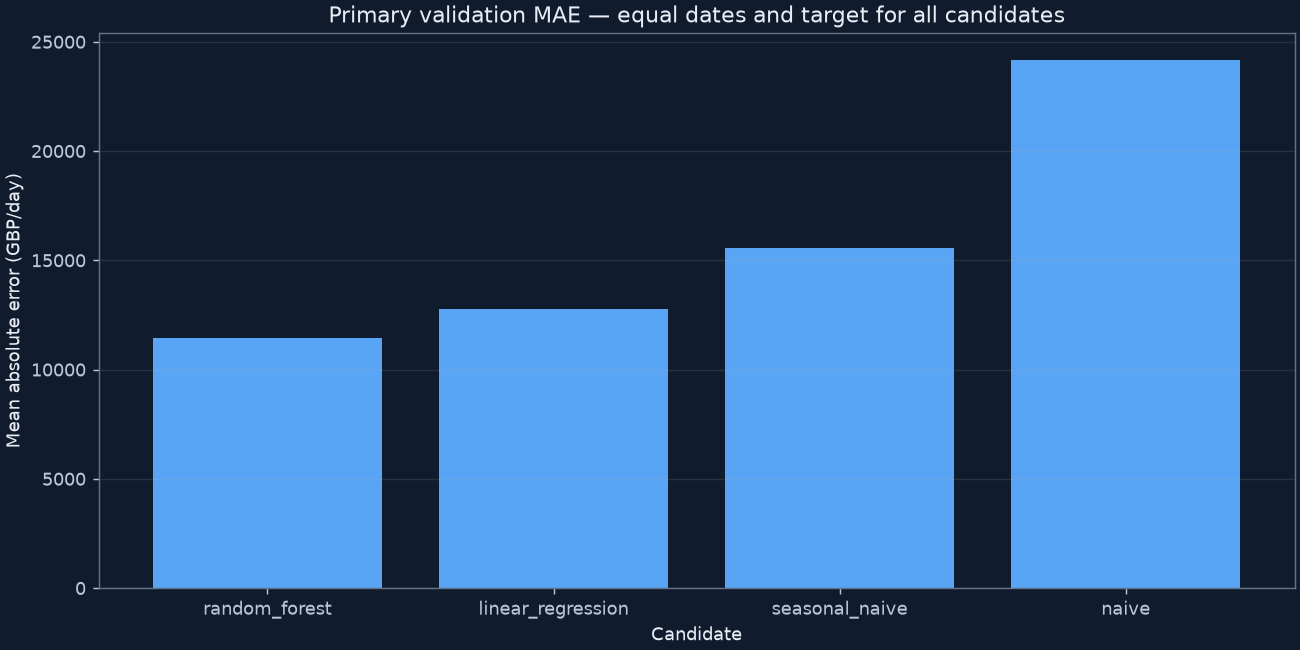

In [6]:
# Reproduce the frozen primary validation, not a new tuning experiment.
validation = rolling_validation(development, split["validation_start"])
comparison = summarize_predictions(validation)
display(comparison)
stored = pd.read_csv(report_dir / "forecast_validation_comparison.csv")
np.testing.assert_allclose(
    comparison.sort_values("model")["mae_gbp"],
    stored.sort_values("model")["mae_gbp"],
    rtol=0,
    atol=1e-6,
)
selected = results["selected_model"]
assert selected == comparison.sort_values(["mae_gbp", "model"]).iloc[0]["model"]
display(Image(filename=str(report_dir / "figures" / "forecast_comparison.png")))

**Interpretation:** compare MAE on identical target/dates. The validation ranking
selects the candidate before test scores are opened. More complexity is not evidence
of predictive improvement. ML weights are frozen at the pretest cutoff for evaluation.

## Final held-out evaluation — fixed selection

Test consists of eight later weekly origins. Within a block, no test actual feeds
predictions. Between blocks, earlier observed test revenue may update context, but
learned weights are never refitted. These are operational weekly forecasts, not a
single 56-day forecast. The CLI persists predictions before this notebook audits them.


,experiment,model,mae_gbp,rmse_gbp,wape_pct,bias_gbp,observations
0,heldout_primary,naive,20978.671786,28049.452796,45.334278,10402.735000,56
1,heldout_primary,random_forest,12344.707215,17396.902901,26.676541,-6379.573175,56
2,heldout_primary,seasonal_naive,11250.169107,16218.794165,24.311277,-2658.581607,56


Validation selected **random_forest**. Lowest test MAE belongs to **seasonal_naive** at **£11,250.17**. The test ranking does not replace the validation selection. This one period does not support general ML superiority.

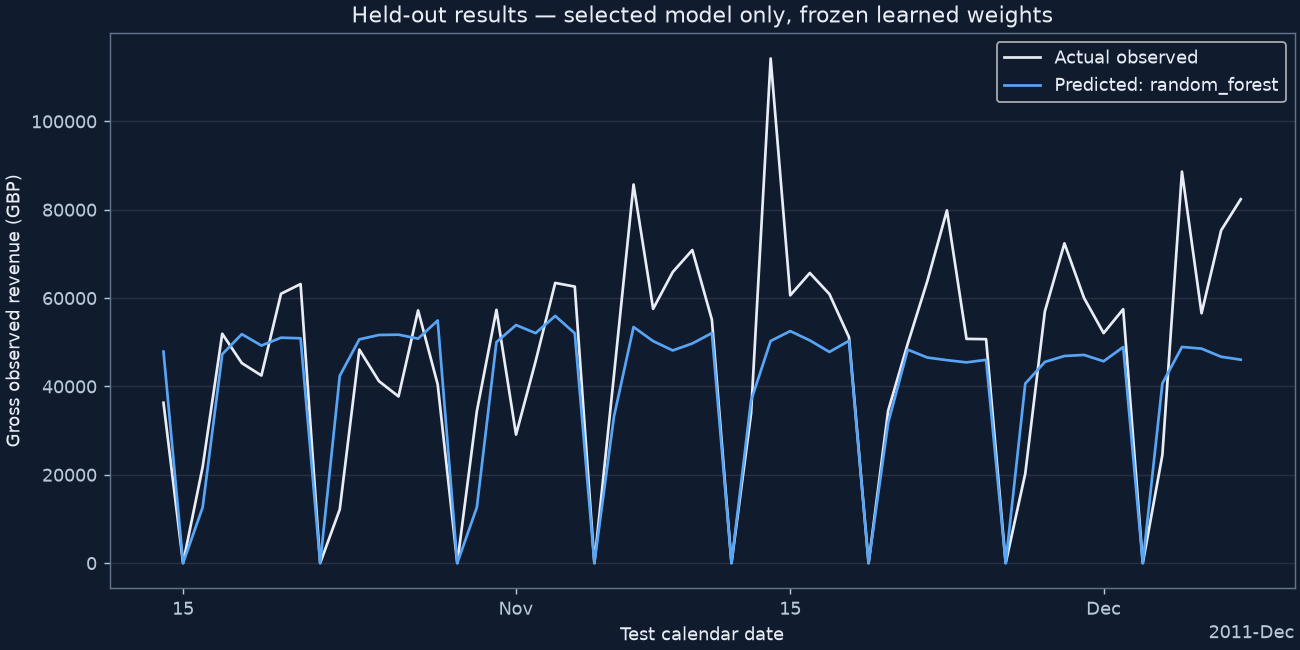

In [7]:
test = pd.read_csv(
    report_dir / "forecast_test_predictions.csv",
    parse_dates=["date", "forecast_origin", "training_cutoff"],
)
assert validation["date"].max() < test["date"].min()
assert (test["training_cutoff"] < pd.Timestamp(split["test_start_date"])).all()
assert test.groupby("model")["training_cutoff"].nunique().eq(1).all()
test_metrics = summarize_predictions(test)
display(test_metrics)
best_test = test_metrics.sort_values("mae_gbp").iloc[0]
display(
    Markdown(
        f"Validation selected **{selected}**. Lowest test MAE belongs to "
        f"**{best_test['model']}** at **£{best_test['mae_gbp']:,.2f}**. "
        "The test ranking does not replace the validation selection. "
        "This one period does not support general ML superiority."
    )
)
display(Image(filename=str(report_dir / "figures" / "forecast_actual_prediction.png")))

**Interpretation:** actuals and predictions are distinct. Large misses and growth
can cause underprediction. Do not attribute this figure's pretest-model metrics to
the separate final refit that later includes test observations.

## Error by horizon and residuals

MAE and RMSE use GBP/day; RMSE emphasizes large misses. WAPE divides summed absolute
errors by summed actual GBP; all-zero denominators are undefined. MAPE is not used.
Horizon is confounded with weekday because every weekly origin falls on the same weekday.


,experiment,model,horizon,mae_gbp,rmse_gbp,wape_pct,bias_gbp,observations
0,heldout_primary,naive,1,6465.907500,9082.792773,12.406911,4562.882500,8
1,heldout_primary,naive,2,56678.252500,57464.348258,NaN,56678.252500,8
2,heldout_primary,naive,3,28680.721250,30278.344769,102.440179,28680.721250,8
3,heldout_primary,naive,4,18385.888750,23058.166611,26.608017,-12420.803750,8
4,heldout_primary,naive,5,12641.566250,15338.671034,23.709957,3360.711250,8
5,heldout_primary,naive,6,12386.943750,14655.418485,20.966928,-2400.233750,8
6,heldout_primary,naive,7,11611.422500,14974.673289,18.631745,-5642.385000,8
7,heldout_primary,random_forest,1,8249.989686,9430.379451,15.830243,-1734.658410,8
8,heldout_primary,random_forest,2,0.000000,0.000000,NaN,0.000000,8
9,heldout_primary,random_forest,3,14091.536684,16778.335720,50.331354,3337.619262,8


,date,horizon,prediction_gbp,forecast_origin,model,model_version,training_cutoff,interpretation,actual_gbp,fold,experiment,residual_gbp
23,2011-10-23,3,42385.990564,2011-10-20,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,12156.57,2,heldout_primary,30229.420564
46,2011-11-01,5,53895.220783,2011-10-27,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,29091.90,3,heldout_primary,24803.320783
128,2011-11-27,3,40640.104589,2011-11-24,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,20279.37,7,heldout_primary,20360.734589
149,2011-12-04,3,40666.787721,2011-12-01,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,24477.47,8,heldout_primary,16189.317721
42,2011-10-28,1,54925.555623,2011-10-27,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,40455.26,3,heldout_primary,14470.295623


,date,horizon,prediction_gbp,forecast_origin,model,model_version,training_cutoff,interpretation,actual_gbp,fold,experiment,residual_gbp
87,2011-11-14,4,50286.398199,2011-11-10,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,114237.40,5,heldout_primary,-63951.001801
150,2011-12-05,4,48931.971426,2011-12-01,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,88620.84,8,heldout_primary,-39688.868574
153,2011-12-08,7,46050.459371,2011-12-01,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,82371.55,8,heldout_primary,-36321.090629
110,2011-11-23,6,45941.302159,2011-11-17,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,79847.00,6,heldout_primary,-33905.697841
66,2011-11-07,4,53447.414499,2011-11-03,random_forest,3.0.0,2011-10-13,retrospective historical demonstration,85705.30,4,heldout_primary,-32257.885501


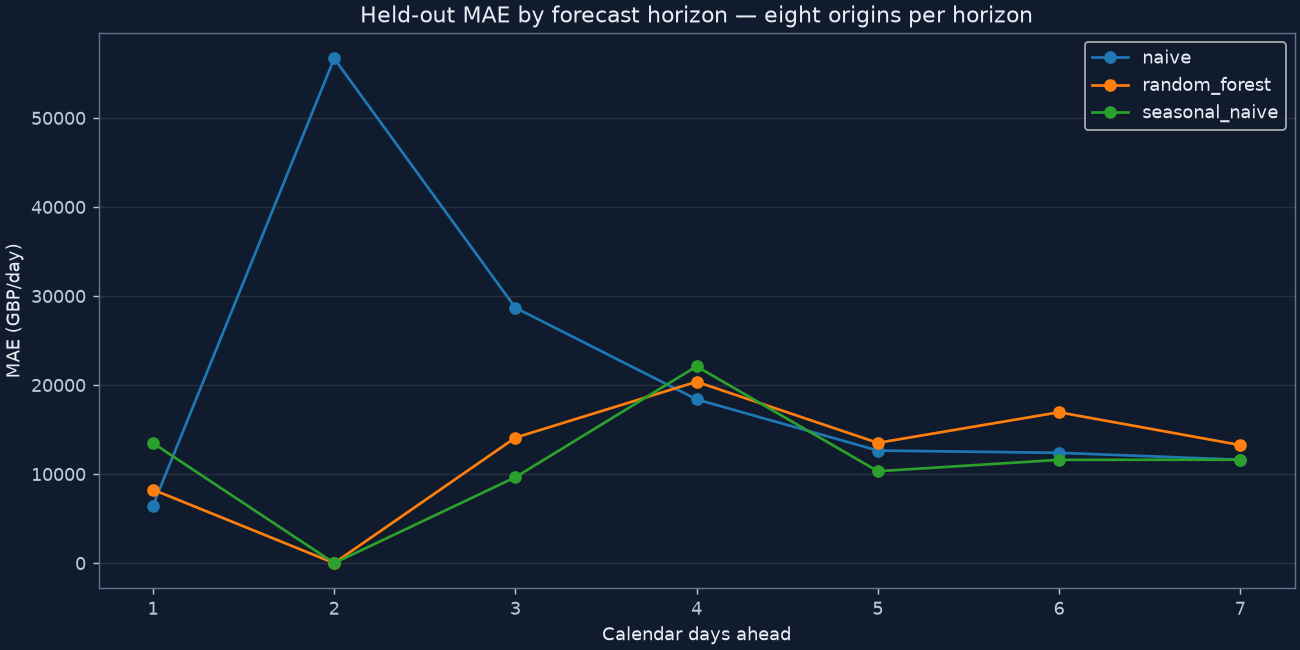

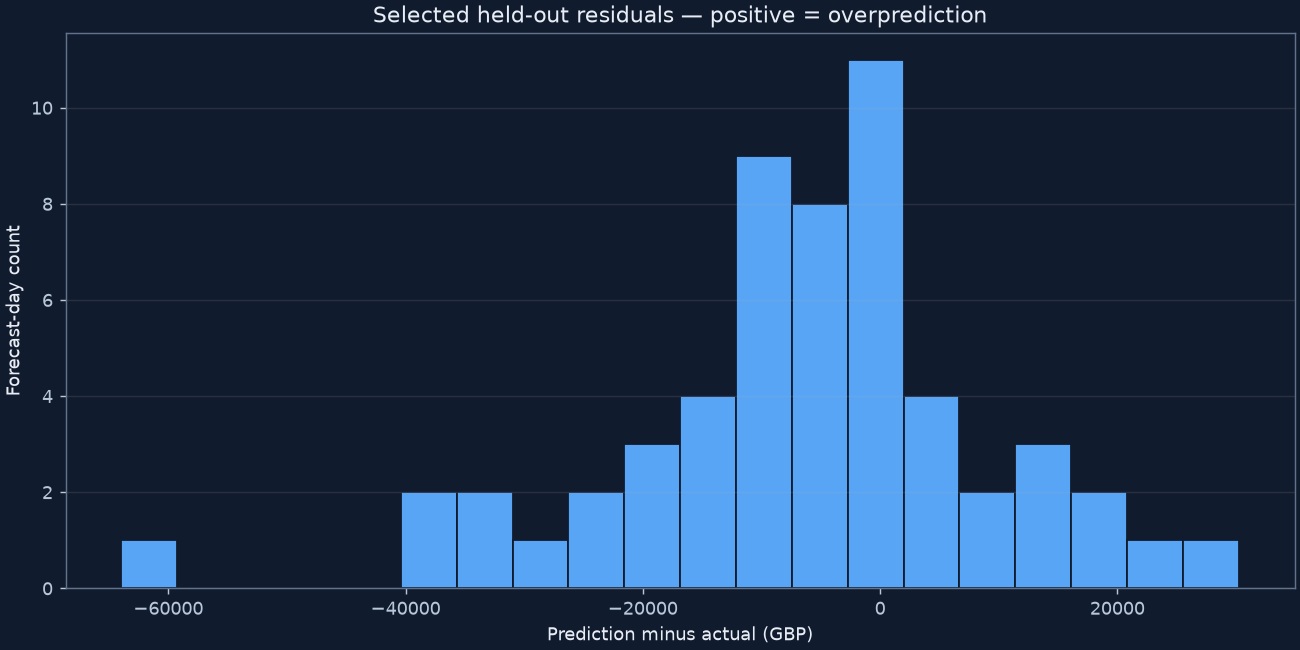

In [8]:
display(summarize_predictions(test, by="horizon"))
selected_test = test.loc[test["model"].eq(selected)].copy()
selected_test["residual_gbp"] = selected_test["prediction_gbp"] - selected_test["actual_gbp"]
display(selected_test.nlargest(5, "residual_gbp"))
display(selected_test.nsmallest(5, "residual_gbp"))
display(Image(filename=str(report_dir / "figures" / "forecast_horizons.png")))
display(Image(filename=str(report_dir / "figures" / "forecast_residuals.png")))

**Interpretation:** positive residuals overpredict; negative ones underpredict.
Eight origins per horizon are limited evidence. Saturday zero observations can make
one horizon appear perfect without demonstrating uniformly reliable forecasting.

## Controlled sensitivity experiments (validation only)

A: learn recurring no-record weekdays from initial training, exclude them from model
training, and forecast zero on those scheduled dates. No future activity flag is read.
B: use initial-training p99 to quantify validation extreme-day error influence;
no outliers are removed from training or primary scores. C: exclude only DOT, POST,
AMAZONFEE and BANK CHARGES from a separate target. M remains ambiguous and included.
Different-target errors are not directly comparable as primary-target improvements.


In [9]:
display(pd.read_csv(report_dir / "forecast_sensitivity_metrics.csv"))
display(pd.DataFrame(results["extreme_influence"]))
display(
    Markdown(
        "Primary selection remains unchanged. Sensitivities diagnose assumptions, "
        "not alternative choices tuned against held-out results."
    )
)

,experiment,model,mae_gbp,rmse_gbp,wape_pct,bias_gbp,observations
0,calendar_training_schedule,linear_regression,12371.755253,18373.731160,38.267285,-5921.755582,56
1,calendar_training_schedule,naive,17240.258000,23190.054495,53.326132,9319.224071,56
2,calendar_training_schedule,random_forest,11716.153120,17768.730397,36.239431,-4713.560125,56
3,calendar_training_schedule,seasonal_naive,15580.520179,21661.318859,48.192369,-967.724821,56
4,evaluation_below_initial_training_p99,linear_regression,10527.773505,13624.876166,36.060895,-2636.444886,53
5,evaluation_below_initial_training_p99,naive,23444.597887,29775.160230,80.305032,19287.106943,53
6,evaluation_below_initial_training_p99,random_forest,9040.343639,12688.673685,30.965986,-2145.524856,53
7,evaluation_below_initial_training_p99,seasonal_naive,13870.995283,19273.387117,47.512469,1568.939434,53
8,excluding_named_charges,linear_regression,12616.084413,18017.495098,39.876678,-5045.293253,56
9,excluding_named_charges,naive,24060.646232,30029.788897,76.050431,16336.407304,56


,model,threshold_gbp,extreme_days,extreme_squared_error_share_pct
0,linear_regression,71392.9177,3,47.297403
1,naive,71392.9177,3,8.641859
2,random_forest,71392.9177,3,51.712762
3,seasonal_naive,71392.9177,3,25.073725


Primary selection remains unchanged. Sensitivities diagnose assumptions, not alternative choices tuned against held-out results.

## Model persistence and seven-day inference

The candidate is refitted on all modeled history only after testing. Metadata clearly
separates evaluation and deployment cutoffs. Load only artifacts generated by the
local trusted training process; checksum integrity does not authenticate a pickle.


,date,horizon,prediction_gbp,forecast_origin,model,model_version,training_cutoff,interpretation
0,2011-12-09,1,66565.618097,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
1,2011-12-10,2,0.000000,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
2,2011-12-11,3,32980.277045,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
3,2011-12-12,4,68354.809207,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
4,2011-12-13,5,65180.142006,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
5,2011-12-14,6,65684.025322,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration
6,2011-12-15,7,65637.918166,2011-12-08,random_forest,3.0.0,2011-12-08,retrospective historical demonstration


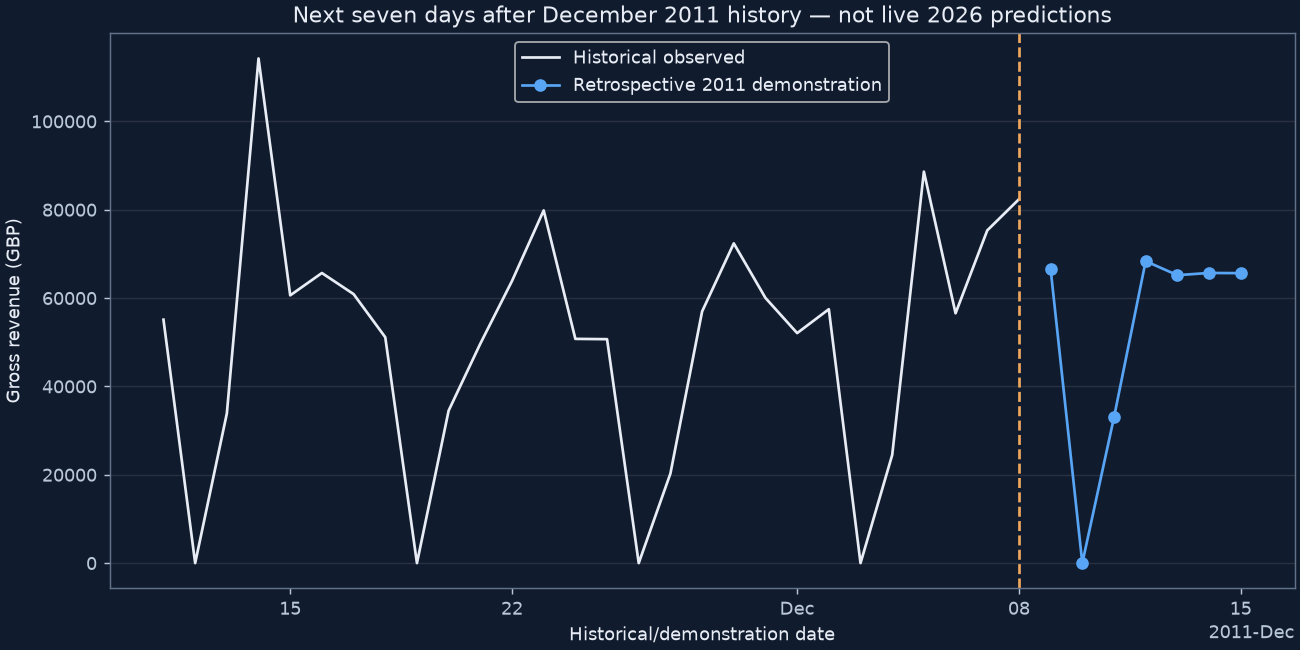

In [10]:
demo = forecast_saved(settings.model_dir, trusted=True)
assert len(demo) == 7
assert (demo["date"] > history.index[-1]).all()
display(demo)
display(Image(filename=str(report_dir / "figures" / "forecast_demonstration.png")))

**Interpretation:** the forecast is for 9–15 December 2011, after the final modeled
observation. The excluded partial day is not used as a future input or complete actual.
This is a retrospective portfolio demonstration, not current revenue or a forecast
interval. Weekly seasonal naive's better held-out result remains visible.

## Conclusions and limitations

The selected forest wins validation but not the held-out weekly-baseline comparison.
Do not claim general superiority or optimize a replacement using these test scores.
Limited history, missing/holiday dates, charges, extreme orders and distribution shift
limit generalization. Thirty-day forecasts require separate evidence. Phase 4 should
show both baseline and candidate performance, historical versus forecast labels,
training cutoff, target/calendar policy and model version. No dashboard is built here.
